# Exploratory Transcriptome Reanalysis of mESC Adipogenesis: ECM Remodelling and Lipid Metabolism

**Study context:** Al-Sayegh et al. (2026), *Adipocyte*  
**Publication:** [https://doi.org/10.1080/21623945.2026.2680625](https://doi.org/10.1080/21623945.2026.2680625)  
**Transcriptome BioProject:** [PRJNA1126392](https://www.ncbi.nlm.nih.gov/bioproject/PRJNA1126392)  
**Proteomics accession:** [PXD078584](https://www.ebi.ac.uk/pride/archive/projects/PXD078584)  
**Processed expression matrix repository:** [Al-Sayegh lab bioinformatics repository](https://github.com/mxa1429/msc-bioinformatics-mohamed-alsayegh)

## Scope and evidence boundaries

This notebook presents **descriptive quality control and exploratory analysis** of a processed expression matrix with three `Neg` and three `Pos` sample columns. It does not reproduce the paper's DESeq2 results or its five-layer MOFA+ integration.

The candidate variance-stabilized (VST) matrix was retrieved from the public repository associated with the study. Its exact processing history and correspondence to the final paper's sample-level analysis input have not been independently verified. Because the matrix contains processed VST values rather than raw counts, this notebook does not use ordinary t-tests or BH-adjusted p-values to declare differentially expressed genes.

The deposited proteomics metadata list nine TMT reporter channels, but a verified reporter-channel-to-condition mapping was not established from the inspected metadata. Accordingly, this notebook does not perform a `Pos`-versus-`Neg` protein comparison or claim cross-omics integration.

### Analyses included
- Input and schema checks, plus descriptive sample-level quality control.
- PCA as a descriptive view of the six processed sample profiles.
- Descriptive summaries of selected candidate genes and small exploratory ECM-remodelling and lipid-metabolism panels.
- Technical validation checks and a run manifest documenting source access, outputs, and key limitations.

### Interpretation boundaries
- The analysis does not establish differential-expression significance; the original count matrix and a suitable count-based model (such as DESeq2) would be needed for that analysis.
- The results do not establish causality or experimental validation.
- Cross-omics agreement and a complete independent multi-omics reanalysis are not claimed.


## 1. Environment and reproducibility

Run this notebook from top to bottom in a fresh Colab runtime. Network downloads can fail if a public URL changes; failures are recorded and not represented as completed analyses.

In [1]:
%pip -q install pandas numpy scipy scikit-learn matplotlib seaborn requests

In [2]:
import os, sys, json, hashlib, platform, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import scipy
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import requests

SEED = 2026
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
DATA_DIR = Path('alsayegh_2026_data')
OUT_DIR = Path('alsayegh_2026_results')
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

SOURCES = {
    'paper': 'https://doi.org/10.1080/21623945.2026.2680625',
    'transcriptome_bioproject': 'https://www.ncbi.nlm.nih.gov/bioproject/PRJNA1126392',
    'candidate_vst_matrix_repository': 'https://github.com/mxa1429/msc-bioinformatics-mohamed-alsayegh',
    'pride_project': 'https://www.ebi.ac.uk/pride/archive/projects/PXD078584',
    'proteomexchange_project': 'https://proteomecentral.proteomexchange.org/?pxid=PXD078584',
}
print('Run timestamp UTC:', datetime.now(timezone.utc).isoformat())
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| NumPy:', np.__version__, '| SciPy:', scipy.__version__)
print('Working directory:', os.getcwd())
display(pd.DataFrame([{'resource': k, 'url': v} for k, v in SOURCES.items()]))

Run timestamp UTC: 2026-10-25T06:58:29.395764+00:00
Python: 3.13.16 | pandas: 2.2.3 | NumPy: 2.1.3 | SciPy: 1.16.3
Working directory: /content


,resource,url
0,paper,https://doi.org/10.1080/21623945.2026.2680625
1,transcriptome_bioproject,https://www.ncbi.nlm.nih.gov/bioproject/PRJNA1...
2,candidate_vst_matrix_repository,https://github.com/mxa1429/msc-bioinformatics-...
3,pride_project,https://www.ebi.ac.uk/pride/archive/projects/P...
4,proteomexchange_project,https://proteomecentral.proteomexchange.org/?p...


## 2. Retrieve and validate the candidate processed expression matrix

The file is a candidate source matrix, not raw counts. We check its schema and numeric values; these checks do not independently prove the biological identity of the samples.

In [3]:
TRANSCRIPTOME_CSV = DATA_DIR / 'vst_matrix_genes.csv'
TRANSCRIPTOME_URLS = [
    'https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/main/Codes/vst_matrix_genes.csv',
    'https://raw.githubusercontent.com/mxa1429/msc-bioinformatics-mohamed-alsayegh/master/Codes/vst_matrix_genes.csv',
]

def download_file(url, destination, timeout=45):
    destination = Path(destination)
    try:
        response = requests.get(url, timeout=timeout, headers={'User-Agent':'Mozilla/5.0'})
        response.raise_for_status()
        if not response.content:
            raise ValueError('Empty response')
        destination.write_bytes(response.content)
        return {'url':url, 'status':'downloaded', 'http_status':response.status_code,
                'bytes':len(response.content), 'sha256':hashlib.sha256(response.content).hexdigest(), 'error':''}
    except Exception as exc:
        return {'url':url, 'status':'failed', 'http_status':getattr(locals().get('response',None),'status_code',None),
                'bytes':0, 'sha256':'', 'error':f'{type(exc).__name__}: {exc}'}

download_log = []
if not TRANSCRIPTOME_CSV.exists():
    for url in TRANSCRIPTOME_URLS:
        attempt = download_file(url, TRANSCRIPTOME_CSV)
        download_log.append(attempt)
        if attempt['status'] == 'downloaded':
            break
if download_log:
    display(pd.DataFrame(download_log))

sample_cols = ['Neg_1','Neg_2','Neg_3','Pos_1','Pos_2','Pos_3']
required_cols = ['gene.names'] + sample_cols
raw = None
if TRANSCRIPTOME_CSV.exists():
    raw = pd.read_csv(TRANSCRIPTOME_CSV)
    missing = [c for c in required_cols if c not in raw.columns]
    if missing:
        raise ValueError(f'Required columns missing: {missing}. Do not guess sample mappings.')
    for c in sample_cols:
        raw[c] = pd.to_numeric(raw[c], errors='coerce')
    if raw[sample_cols].notna().sum().sum() == 0:
        raise ValueError('No numeric expression values found.')
    sha256 = hashlib.sha256(TRANSCRIPTOME_CSV.read_bytes()).hexdigest()
    print('Imported candidate matrix:', raw.shape)
    print('SHA-256:', sha256)
    print('Unique non-empty symbols:', raw['gene.names'].dropna().astype(str).str.strip().replace('',np.nan).nunique())
    display(raw.head())
else:
    raise FileNotFoundError('Could not retrieve candidate VST matrix. Review download log above; do not report analyses as completed.')

,url,status,http_status,bytes,sha256,error
0,https://raw.githubusercontent.com/mxa1429/msc-...,downloaded,200,3760232,69b7e184ee9ab762d8086c818f40befb5c55ff6ba7ef19...,


Imported candidate matrix: (46603, 7)
SHA-256: 69b7e184ee9ab762d8086c818f40befb5c55ff6ba7ef19a37353f8ae92f8df88
Unique non-empty symbols: 46475


,gene.names,Neg_1,Neg_2,Neg_3,Pos_1,Pos_2,Pos_3
0,Gnai3,12.722687,12.761691,12.873918,13.258710,13.282136,13.002556
1,Pbsn,3.872154,3.872154,3.872154,3.872154,3.872154,3.872154
2,Cdc45,8.090108,8.071735,8.020891,8.801457,8.829139,8.588195
3,H19,16.510410,16.656625,16.502528,14.908266,15.428432,16.144464
4,Scml2,7.285921,7.205858,7.069953,6.772985,6.812367,6.930409


## 3. Sample-level quality control

Distribution and correlation plots are descriptive only. High correlations do not prove sample labels or replicate identities.

,value
matrix_rows,46603
non-empty_gene_symbol_rows,46603
unique_non-empty_gene_symbols,46475
rows_with_duplicate_symbol,222
missing_expression_values,0
non-finite_expression_values_before_cleaning,0
constant_rows,17333


,count,mean,std,min,median,max
Neg_1,46603.0,5.770437,2.720133,3.872154,4.224485,18.535227
Neg_2,46603.0,5.766372,2.738072,3.872154,4.241713,18.294579
Neg_3,46603.0,5.769414,2.718215,3.872154,4.237477,18.667596
Pos_1,46603.0,5.733873,2.714165,3.872154,4.252834,18.308153
Pos_2,46603.0,5.730814,2.726265,3.872154,4.237592,18.494380
Pos_3,46603.0,5.742212,2.739536,3.872154,3.872154,18.528889


Sample correlation matrix


,Neg_1,Neg_2,Neg_3,Pos_1,Pos_2,Pos_3
Neg_1,1.000,0.996,0.997,0.970,0.969,0.969
Neg_2,0.996,1.000,0.996,0.971,0.969,0.968
Neg_3,0.997,0.996,1.000,0.971,0.970,0.970
Pos_1,0.970,0.971,0.971,1.000,0.996,0.991
Pos_2,0.969,0.969,0.970,0.996,1.000,0.994
Pos_3,0.969,0.968,0.970,0.991,0.994,1.000


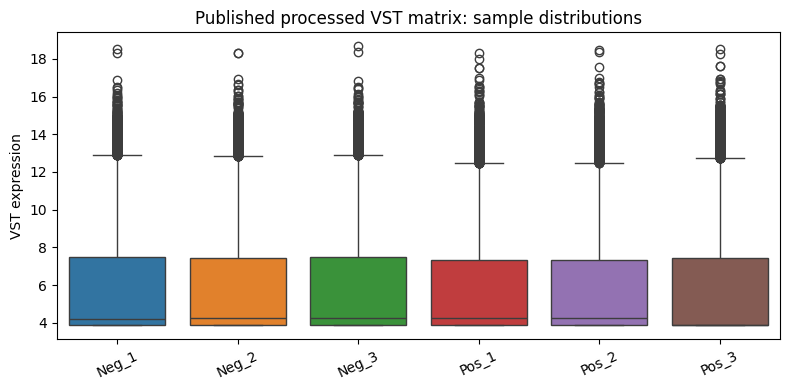

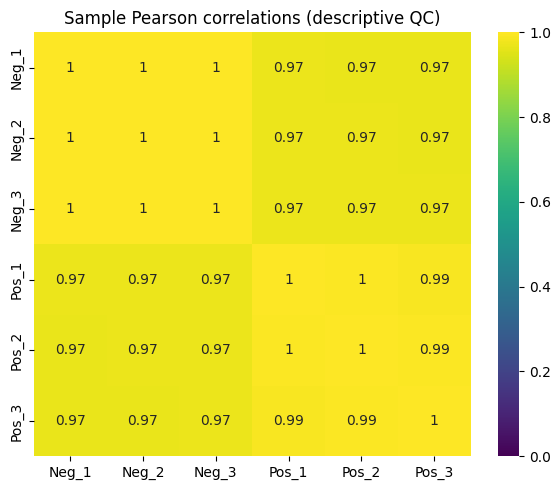

In [4]:
condition = pd.Series(['Neg']*3 + ['Pos']*3, index=sample_cols, name='condition')
expr = raw[sample_cols].replace([np.inf,-np.inf], np.nan)
qc = {
    'matrix_rows': int(len(raw)),
    'non-empty_gene_symbol_rows': int(raw['gene.names'].notna().sum()),
    'unique_non-empty_gene_symbols': int(raw['gene.names'].astype('string').str.strip().replace('',pd.NA).nunique()),
    'rows_with_duplicate_symbol': int(raw['gene.names'].duplicated(keep=False).sum()),
    'missing_expression_values': int(expr.isna().sum().sum()),
    'non-finite_expression_values_before_cleaning': int((~np.isfinite(raw[sample_cols].to_numpy(dtype=float))).sum()),
    'constant_rows': int((expr.std(axis=1,ddof=1).fillna(0) == 0).sum()),
}
display(pd.Series(qc, name='value').to_frame())
display(expr.agg(['count','mean','std','min','median','max']).T)
print('Sample correlation matrix')
display(expr.corr().round(3))

fig, ax = plt.subplots(figsize=(8,4))
sns.boxplot(data=expr, ax=ax)
ax.set_title('Published processed VST matrix: sample distributions')
ax.set_ylabel('VST expression')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(expr.corr(), annot=True, vmin=0, vmax=1, cmap='viridis', ax=ax)
ax.set_title('Sample Pearson correlations (descriptive QC)')
plt.tight_layout(); plt.show()

## 4. Gene-symbol handling and sample-level PCA

Repeated gene symbols are collapsed by the median within each sample. This is a pragmatic descriptive rule because stable gene identifiers and the original count matrix are not present in this input. It is not a substitute for resolving duplicates at the source. PCA uses only complete, non-constant rows.

Rows before symbol aggregation: 46603
Unique symbols after aggregation: 46475
Symbols with missing values after aggregation: 0
Complete variable genes used for PCA: 29234
Explained variance ratio: [0.4368 0.2075]


,PC1,PC2,condition
Neg_1,117.157524,22.177725,Neg
Neg_2,119.466376,-22.482791,Neg
Neg_3,101.637132,3.019547,Neg
Pos_1,-105.052693,-120.595340,Pos
Pos_2,-121.746564,-24.414361,Pos
Pos_3,-111.461775,142.295219,Pos


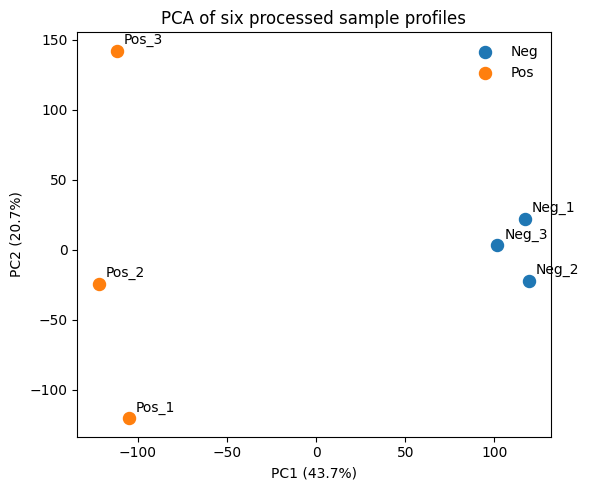

In [5]:
tmp = raw[['gene.names'] + sample_cols].copy()
tmp['gene.names'] = tmp['gene.names'].astype('string').str.strip()
tmp = tmp[tmp['gene.names'].notna() & (tmp['gene.names'] != '')]
tmp[sample_cols] = tmp[sample_cols].replace([np.inf,-np.inf], np.nan)
agg = tmp.groupby('gene.names', sort=True)[sample_cols].median()
print('Rows before symbol aggregation:', len(tmp))
print('Unique symbols after aggregation:', len(agg))
print('Symbols with missing values after aggregation:', int(agg.isna().any(axis=1).sum()))

pca_matrix = agg.dropna(axis=0, how='any')
pca_matrix = pca_matrix.loc[pca_matrix.std(axis=1, ddof=1) > 0]
if pca_matrix.shape[0] >= 2:
    X = StandardScaler().fit_transform(pca_matrix.T)
    pca = PCA(n_components=2, random_state=SEED)
    scores = pca.fit_transform(X)
    pca_df = pd.DataFrame(scores, columns=['PC1','PC2'], index=sample_cols)
    pca_df['condition'] = condition
    print('Complete variable genes used for PCA:', len(pca_matrix))
    print('Explained variance ratio:', pca.explained_variance_ratio_.round(4))
    display(pca_df)
    fig, ax = plt.subplots(figsize=(6,5))
    for cond, group in pca_df.groupby('condition'):
        ax.scatter(group.PC1, group.PC2, s=75, label=cond)
        for sample, row in group.iterrows():
            ax.annotate(sample, (row.PC1,row.PC2), xytext=(5,5), textcoords='offset points')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title('PCA of six processed sample profiles')
    ax.legend(frameon=False); plt.tight_layout(); plt.show()
else:
    pca_df = pd.DataFrame()
    print('PCA skipped: insufficient complete, variable genes.')

## 5. Pre-specified candidate genes: descriptive contrast only

The paper discusses candidate genes including Lpl, Acer3, Plg, Itga5, Igfbp6 and Pik3cg. The paper contains an inconsistency between the abstract and main text concerning the validation-candidate list; this notebook uses the combined list only as an exploratory panel. Values below are descriptive summaries of the imported VST matrix, not independent validation and not differential-expression significance tests.

,gene,present,Neg_mean,Neg_SD,Pos_mean,Pos_SD,mean_difference_Pos_minus_Neg,interpretation
0,Lpl,True,10.057078,0.195692,13.190349,0.762461,3.133270,Descriptive only; no p-value or FDR claim.
1,Acer3,True,10.135163,0.062463,8.766751,0.167154,-1.368411,Descriptive only; no p-value or FDR claim.
2,Plg,True,4.839360,0.209815,3.872154,0.000000,-0.967206,Descriptive only; no p-value or FDR claim.
3,Itga5,True,11.652529,0.147662,12.425978,0.094873,0.773449,Descriptive only; no p-value or FDR claim.
4,Igfbp6,True,6.445853,0.198315,11.286436,0.418620,4.840583,Descriptive only; no p-value or FDR claim.
5,Pik3cg,True,7.350070,0.246366,4.535938,0.147035,-2.814132,Descriptive only; no p-value or FDR claim.


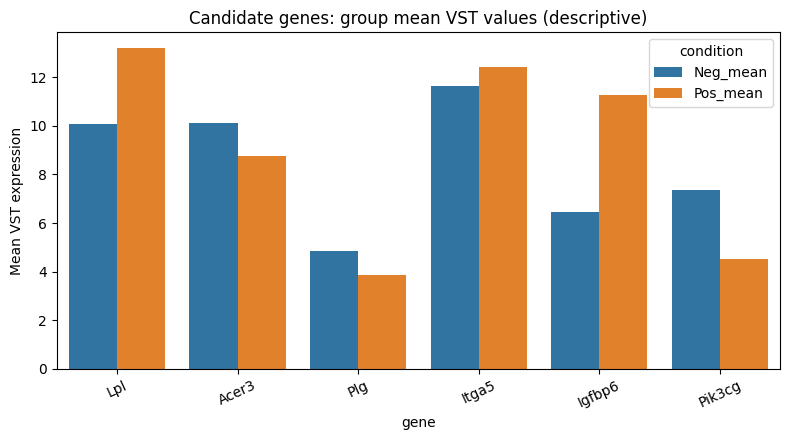

In [6]:
candidate_genes = ['Lpl','Acer3','Plg','Itga5','Igfbp6','Pik3cg']
summary_rows = []
for gene in candidate_genes:
    if gene in agg.index:
        neg = agg.loc[gene, ['Neg_1','Neg_2','Neg_3']].astype(float)
        pos = agg.loc[gene, ['Pos_1','Pos_2','Pos_3']].astype(float)
        summary_rows.append({
            'gene':gene, 'present':True,
            'Neg_mean':float(neg.mean()), 'Neg_SD':float(neg.std(ddof=1)),
            'Pos_mean':float(pos.mean()), 'Pos_SD':float(pos.std(ddof=1)),
            'mean_difference_Pos_minus_Neg':float(pos.mean()-neg.mean()),
            'interpretation':'Descriptive only; no p-value or FDR claim.'
        })
    else:
        summary_rows.append({'gene':gene,'present':False,'Neg_mean':np.nan,'Neg_SD':np.nan,
                             'Pos_mean':np.nan,'Pos_SD':np.nan,'mean_difference_Pos_minus_Neg':np.nan,
                             'interpretation':'Not found under exact symbol match.'})
candidate_report = pd.DataFrame(summary_rows)
display(candidate_report)
candidate_report.to_csv(OUT_DIR/'candidate_gene_descriptive_summary.csv', index=False)

present = candidate_report[candidate_report['present']].copy()
if len(present):
    plot_df = present.melt(id_vars='gene', value_vars=['Neg_mean','Pos_mean'], var_name='condition', value_name='mean_VST')
    fig, ax = plt.subplots(figsize=(8,4.5))
    sns.barplot(data=plot_df, x='gene', y='mean_VST', hue='condition', ax=ax)
    ax.set_title('Candidate genes: group mean VST values (descriptive)')
    ax.set_ylabel('Mean VST expression'); ax.tick_params(axis='x', rotation=25)
    plt.tight_layout(); plt.show()

## 6. Exploratory ECM and lipid-metabolism panels

These small hand-curated panels are hypothesis-oriented summaries, not formal pathway-enrichment tests. The lists are intentionally visible and should be described as a priori exploratory panels. Missing genes are reported rather than imputed.

In [7]:
# Small, explicit panels informed by the study's ECM-remodelling and lipid-metabolism themes.
# These are not comprehensive pathway definitions.
gene_panels = {
    'ECM_remodelling_exploratory': ['Col1a1','Col3a1','Col12a1','Thbs2','Lama1','Itga5'],
    'Lipid_metabolism_exploratory': ['Lpl','Fasn','Scd1','Acer3','Sirt1'],
}
panel_rows = []
for panel, genes in gene_panels.items():
    found = [g for g in genes if g in agg.index]
    for gene in genes:
        if gene not in agg.index:
            panel_rows.append({'panel':panel,'gene':gene,'present':False,'Neg_mean':np.nan,'Pos_mean':np.nan,'difference_Pos_minus_Neg':np.nan})
        else:
            neg = agg.loc[gene,['Neg_1','Neg_2','Neg_3']].astype(float)
            pos = agg.loc[gene,['Pos_1','Pos_2','Pos_3']].astype(float)
            panel_rows.append({'panel':panel,'gene':gene,'present':True,'Neg_mean':float(neg.mean()),'Pos_mean':float(pos.mean()),'difference_Pos_minus_Neg':float(pos.mean()-neg.mean())})
panel_report = pd.DataFrame(panel_rows)
display(panel_report)
panel_report.to_csv(OUT_DIR/'exploratory_ECM_lipid_gene_panels.csv', index=False)
print('Interpretation rule: panel-level direction summaries are descriptive; no pathway significance is calculated.')

,panel,gene,present,Neg_mean,Pos_mean,difference_Pos_minus_Neg
0,ECM_remodelling_exploratory,Col1a1,True,16.234090,16.924190,0.690100
1,ECM_remodelling_exploratory,Col3a1,True,14.928685,15.691224,0.762539
2,ECM_remodelling_exploratory,Col12a1,True,12.458896,13.984275,1.525379
3,ECM_remodelling_exploratory,Thbs2,True,10.033373,13.565440,3.532067
4,ECM_remodelling_exploratory,Lama1,True,13.729992,15.764143,2.034151
5,ECM_remodelling_exploratory,Itga5,True,11.652529,12.425978,0.773449
6,Lipid_metabolism_exploratory,Lpl,True,10.057078,13.190349,3.133270
7,Lipid_metabolism_exploratory,Fasn,True,12.578578,12.085228,-0.493350
8,Lipid_metabolism_exploratory,Scd1,True,10.253181,11.226538,0.973358
9,Lipid_metabolism_exploratory,Acer3,True,10.135163,8.766751,-1.368411


Interpretation rule: panel-level direction summaries are descriptive; no pathway significance is calculated.


## 7. Proteomics availability and interpretation boundary

PRIDE PXD078584 contains a processed mzTab protein quantification file. Its metadata indicates nine TMT reporter channels (126, 127N, 127C, 128N, 128C, 129N, 129C, 130N, 130C) and eleven listed MS runs. The project file listing did not provide an SDRF/sample annotation file, and the channel descriptions alone do not map reporter channels to Pos/Neg biological replicates. Consequently, protein-level Pos-versus-Neg testing and cross-omics integration are **not performed** in this notebook. The PRIDE MultiQC job failure is not itself evidence that the biological data are poor quality.

In [8]:
proteomics_status = pd.DataFrame([{
    'layer':'proteomics',
    'accession':'PXD078584',
    'processed_file':'03032025_Alsayegh_Quantified_Proteins_Result.mzTab',
    'processed_file_size_bytes':31662835,
    'reported_TMT_channels':9,
    'MS_runs_listed_in_mzTab_metadata':11,
    'verified_channel_to_condition_map':False,
    'sample_level_comparison_performed':False,
    'reason':'No verified reporter-channel-to-biological-condition mapping available from inspected project metadata.'
}])
display(proteomics_status)
proteomics_status.to_csv(OUT_DIR/'proteomics_availability_status.csv', index=False)

,layer,accession,processed_file,processed_file_size_bytes,reported_TMT_channels,MS_runs_listed_in_mzTab_metadata,verified_channel_to_condition_map,sample_level_comparison_performed,reason
0,proteomics,PXD078584,03032025_Alsayegh_Quantified_Proteins_Result.m...,31662835,9,11,False,False,No verified reporter-channel-to-biological-con...


## 8. Technical validation and limitations

A passing technical check validates only the stated file/schema conditions. It does not establish biological provenance or justify inferential conclusions.

In [9]:
checks = []
def check(name, passed, detail):
    checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})

check('Candidate expression matrix loaded', raw is not None, str(TRANSCRIPTOME_CSV))
check('Required sample columns present', all(c in raw.columns for c in required_cols), str(required_cols))
check('At least one finite numeric expression value', bool(np.isfinite(raw[sample_cols].to_numpy(dtype=float)).any()), 'Finite numeric values found.')
check('Gene symbols aggregated uniquely', bool(agg.index.is_unique), f'{len(agg)} unique symbols after median aggregation.')
check('PCA input has six samples', pca_matrix.shape[1] == 6 if 'pca_matrix' in globals() else False, f'PCA matrix shape: {getattr(pca_matrix,"shape",None)}')
check('No Pos/Neg proteomics inference without mapping', not bool(proteomics_status.iloc[0]['sample_level_comparison_performed']), 'Protein comparison explicitly withheld because mapping is unverified.')
validation_df = pd.DataFrame(checks)
display(validation_df)
print(f'Technical checks passed: {int(validation_df.passed.sum())}/{len(validation_df)}')
if not validation_df.passed.all():
    print('At least one technical check failed; review before presenting this notebook.')
validation_df.to_csv(OUT_DIR/'technical_validation_checks.csv', index=False)

,check,passed,detail
0,Candidate expression matrix loaded,True,alsayegh_2026_data/vst_matrix_genes.csv
1,Required sample columns present,True,"['gene.names', 'Neg_1', 'Neg_2', 'Neg_3', 'Pos..."
2,At least one finite numeric expression value,True,Finite numeric values found.
3,Gene symbols aggregated uniquely,True,46475 unique symbols after median aggregation.
4,PCA input has six samples,True,"PCA matrix shape: (29234, 6)"
5,No Pos/Neg proteomics inference without mapping,True,Protein comparison explicitly withheld because...


Technical checks passed: 6/6


## 9. Export results and run manifest

The manifest records the matrix hash, source URLs, outputs and key limitations. It intentionally does not report the Welch-test/FDR results from the previous notebook version because those inferential claims are not retained in this revised analysis.

In [10]:
run_manifest = {
    'project_title':'Exploratory analysis of mESC adipogenic differentiation in the context of Al-Sayegh et al. 2026',
    'run_timestamp_utc':datetime.now(timezone.utc).isoformat(),
    'random_seed':SEED,
    'sources':SOURCES,
    'candidate_expression_matrix':{
        'path':str(TRANSCRIPTOME_CSV),
        'sha256':hashlib.sha256(TRANSCRIPTOME_CSV.read_bytes()).hexdigest(),
        'shape':list(raw.shape),
        'columns':list(raw.columns),
        'provenance_status':'Candidate matrix from public repository; exact correspondence to final 2026 analysis input must be confirmed.'
    },
    'transcriptome_qc':qc,
    'unique_symbols_after_median_aggregation':int(len(agg)),
    'proteomics_status':proteomics_status.iloc[0].to_dict(),
    'technical_checks':validation_df.to_dict(orient='records'),
    'interpretation_boundaries':[
        'No count-based DESeq2 differential-expression analysis was performed because the imported matrix contains processed VST values, not raw counts.',
        'No Welch-test p-values or BH-FDR discoveries are claimed.',
        'PCA, candidate gene contrasts and small gene panels are descriptive/exploratory only.',
        'Proteomics Pos/Neg comparison was withheld because the TMT reporter channel-to-condition map is unverified.',
        'No five-layer multi-omics integration was performed.',
        'Three samples per group provide limited power; descriptive differences are not causal evidence.',
    ]
}
(OUT_DIR/'run_manifest.json').write_text(json.dumps(run_manifest, indent=2, default=str), encoding='utf-8')
print('Saved results to:', OUT_DIR.resolve())
for path in sorted(OUT_DIR.glob('*')):
    print(f'- {path.name} ({path.stat().st_size:,} bytes)')

Saved results to: /content/alsayegh_2026_results
- candidate_gene_descriptive_summary.csv (942 bytes)
- exploratory_ECM_lipid_gene_panels.csv (1,067 bytes)
- proteomics_availability_status.csv (389 bytes)
- run_manifest.json (3,567 bytes)
- technical_validation_checks.csv (557 bytes)


## 10. Conclusion and limitations

This exploratory analysis checks the structure and sample-level patterns of a repository-provided, processed mouse embryonic stem-cell adipogenesis expression matrix. It summarizes selected candidate genes and small, explicitly defined extracellular matrix (ECM)-remodelling and lipid-metabolism panels. These panels are exploratory summaries, not formal pathway tests. PCA and group summaries are descriptive and do not establish causality or statistical significance.

The principal limitations are data provenance and inferential scope. The available matrix contains VST values rather than raw counts, so this notebook does not reproduce the paper's DESeq2 analysis. Proteomics comparisons are withheld because the reporter-channel-to-condition mapping could not be verified. The work should therefore be interpreted as an **exploratory transcriptome quality-control and descriptive analysis**, not a complete independent multi-omics reanalysis.

## References and data sources

1. Al-Sayegh et al. (2026). *Multi-omics integration reveals convergent extracellular matrix remodelling and lipid metabolic reprogramming as central axes of adipocyte differentiation from mouse embryonic stem cells.* [https://doi.org/10.1080/21623945.2026.2680625](https://doi.org/10.1080/21623945.2026.2680625)
2. Al-Sayegh lab bioinformatics repository, including the candidate processed expression matrix `Codes/vst_matrix_genes.csv`. [https://github.com/mxa1429/msc-bioinformatics-mohamed-alsayegh](https://github.com/mxa1429/msc-bioinformatics-mohamed-alsayegh)
3. NCBI BioProject PRJNA1126392. [https://www.ncbi.nlm.nih.gov/bioproject/PRJNA1126392](https://www.ncbi.nlm.nih.gov/bioproject/PRJNA1126392)
4. PRIDE project PXD078584. [https://www.ebi.ac.uk/pride/archive/projects/PXD078584](https://www.ebi.ac.uk/pride/archive/projects/PXD078584)

The repository matrix is treated as a candidate processed input: its exact correspondence to the final paper's sample-level analysis input has not been independently established. Exploratory differences reported here should not be described as statistically significant discoveries.
